# 🎯 Logistic Regression: from Zero to Confident
### Project: Customer Churn Predictor

**Churn** means a customer leaves (cancels their subscription). Our job: look at a customer and estimate **how likely they are to leave**, so a company can try to keep them.

**How to use this notebook**
- Run cells top to bottom. Every code cell is short and commented.
- Before each code cell: *what we're about to do and why*. After: *what we just saw*.
- Every concept follows the same 7 steps: **idea → analogy → tiny example → math in words → code line by line → common mistake → check yourself**.
- Stuck? Tell your mentor: **"explain simpler"** and the last idea gets a new analogy and a smaller example.
- Unknown word? Look at the **Glossary** right below. It grows as we learn.

**Map of the journey**
1. Theory in plain English
2. Data exploration and preprocessing
3. Logistic regression from scratch (NumPy only)
4. scikit-learn: binary and multi-class (Iris)
5. Metrics: how do we know it's good?
6. Threshold selection as a business decision (₹ costs)
7. Failure modes: class imbalance and calibration
8. Practice: 8 "prove it" questions, 3 coding exercises, 1 extension


## 📚 Glossary (grows as we learn - every new term is added here)

| Term | Plain-English meaning |
|---|---|
| **Classification** | Predicting a category (like 'stays' or 'leaves') instead of a number. |
| **Binary classification** | Classification with exactly two categories, usually called 0 and 1. |
| **Churn** | A customer leaving / cancelling. We label leaving = 1, staying = 0. |
| **Probability** | A number from 0 to 1 saying how likely something is. 0 = impossible, 1 = certain. |
| **Feature** | One input column we use to predict (e.g. months as a customer). |
| **Label / target** | The answer we want to predict (churned or not). |
| **NumPy** | A Python library for fast maths on lists of numbers (arrays). |
| **Odds** | Chance it happens divided by chance it doesn't. p=0.8 gives odds of 4 ('4 to 1'). |
| **Logarithm (ln)** | Answers 'e to what power gives this number?'. ln(1)=0, ln(4)≈1.386. |
| **Log-odds (logit)** | ln(odds). Ranges over all real numbers; 0 means 50/50. |
| **Weight** | A number saying how much a feature pushes the score up or down. The model learns these. |
| **Bias (intercept)** | The starting score when every feature is zero. |
| **Score (z)** | The raw straight-line answer b + w·x before squashing into a probability. |
| **Sigmoid** | The squasher 1/(1+e^-z). Turns any number into a value between 0 and 1. |
| **e (Euler's number)** | A constant ≈ 2.718 used in growth and probability maths. |
| **Linear regression** | Fits a straight line to predict a number. Great for prices, bad for yes/no. |
| **Log-loss (cross-entropy)** | A score that punishes confident wrong predictions heavily. Lower is better. |
| **Likelihood** | The probability, under the model, of seeing exactly the real outcomes. |
| **Maximum likelihood** | Choosing weights that make the real data as likely as possible. |
| **Decision boundary** | The line/surface where the model's probability equals the threshold (usually 0.5). |
| **Threshold** | How sure the model must be before we say 'yes' (act). Often 0.5, but a business choice. |
| **Linear classifier** | A model whose decision boundary is a straight line or flat plane. |

# Step 1 - Theory in plain English

We will learn six ideas, in this order: **odds → log-odds → sigmoid → why not linear regression → log-loss → decision boundary**.
First, a setup cell so our code can draw plots and do maths.

### What we're about to do and why
Import the tools once. `numpy` = maths, `matplotlib` = drawing plots. We fix a random seed so you get the same numbers I do.

In [1]:
import numpy as np                    # NumPy: fast maths on arrays of numbers
import matplotlib.pyplot as plt      # matplotlib: draws plots
import warnings; warnings.filterwarnings("ignore")   # hide noisy, harmless warnings
np.random.seed(42)                   # fix randomness so results repeat every run
plt.rcParams["figure.figsize"] = (6, 4)   # default plot size (width, height) in inches
plt.rcParams["axes.grid"] = True          # light grid makes plots easier to read

### What we just saw
Nothing visible, and that's fine: the tools are loaded. (`np` is our shortcut name for NumPy, `plt` for matplotlib.)

---
## 1.0 The problem: a yes/no question
**Idea:** Logistic regression answers a yes/no question by giving a *probability* of "yes".

**Analogy:** Think of a **probability dial** from 0 to 100%. For each customer the model turns the dial to say "I'm 80% sure this person will leave". *Then* a human picks how sure is sure enough to act.

**Name check:** despite the word "regression" in its name, logistic regression is used for **classification**. It's a historical naming accident.

**Common beginner mistake:** thinking the model outputs "yes" or "no". It outputs a **probability**. The yes/no comes later, from a threshold (Step 6).

---
## 1.1 Odds
**Idea (one sentence):** Odds compare how likely something is to happen versus how likely it is *not* to happen.

**Analogy:** Betting odds. "4 to 1" means for every 1 time it fails, it happens 4 times.

**Tiny example by hand:**
- A customer has a probability of leaving of **p = 0.8** (80%).
- Chance of *not* leaving = 1 − 0.8 = **0.2**.
- Odds = 0.8 ÷ 0.2 = **4**. ("4 to 1 they leave")
- If p = 0.5 → odds = 0.5 ÷ 0.5 = **1** ("even odds", a coin flip).
- If p = 0.2 → odds = 0.2 ÷ 0.8 = **0.25** (unlikely).

**The math, every symbol in words:**

`odds = p / (1 − p)`
- `p` = the probability the event happens (a number between 0 and 1).
- `1 − p` = the probability it does not happen.
- `/` = divide.

Odds range from 0 up to infinity (∞). They never go negative.

**Common beginner mistake:** mixing up *odds* and *probability*. Odds of 4 does **not** mean 4% or 40%. It means 80%.

In [2]:
def odds(p):                  # turn a probability p into odds
    return p / (1 - p)       # chance it happens divided by chance it doesn't

for p in [0.2, 0.5, 0.8, 0.99]:        # try four probabilities
    print(f"p = {p:<4}  ->  odds = {odds(p):.2f}")   # print p and its odds (2 decimals)

p = 0.2   ->  odds = 0.25
p = 0.5   ->  odds = 1.00
p = 0.8   ->  odds = 4.00
p = 0.99  ->  odds = 99.00


### What we just saw (code line by line)
- `def odds(p):` defines a reusable recipe named `odds` that takes one input `p`.
- `return p / (1 - p)` hands back the answer of the formula.
- `for p in [...]:` repeats the next line once for each probability in the list.
- `print(f"...{...}")` prints text; the `{}` parts get replaced by real numbers.

Notice p = 0.99 gives odds = 99. Odds explode as p nears 1. That's awkward, so we take one more step.

### 🧠 Check yourself

If p = 0.75, what are the odds?

<details><summary>👉 Click for the answer</summary>

Odds = 0.75 ÷ 0.25 = **3** (3 to 1).

</details>

---
## 1.2 Log-odds (the "logit")
**Refresher: what is a logarithm (log)?** `ln(x)` answers: *"e raised to what power gives x?"* (`e` ≈ 2.718, a special constant.)
- `ln(1) = 0` because e⁰ = 1.
- `ln(e) = 1` because e¹ = e.
- `ln(4) ≈ 1.386`.
- `ln` of a number **below 1 is negative**: `ln(0.25) ≈ −1.386`.
- Logs turn *multiplying* into *adding*: `ln(a×b) = ln(a) + ln(b)`. Keep that, we'll use it later.

**Idea (one sentence):** Log-odds are just the natural log of the odds, which stretches the 0-to-∞ odds onto the whole number line, −∞ to +∞.

**Analogy:** A thermometer that goes below zero. Odds only have "above 0"; log-odds give us a fair scale with a neutral middle (0 = 50/50), positive = "likely yes", negative = "likely no".

**Tiny example by hand:**
- p = 0.8 → odds = 4 → log-odds = ln(4) = **1.386**
- p = 0.5 → odds = 1 → log-odds = ln(1) = **0**
- p = 0.2 → odds = 0.25 → log-odds = ln(0.25) = **−1.386** (mirror image!)

**The math in words:** `log-odds = ln( p / (1 − p) )`, "take the probability, convert to odds, then take the log".

**Why we care:** logistic regression says *the log-odds are a straight-line combination of the features*:
`z = b + w₁·x₁ + w₂·x₂ + …`
- `z` = the log-odds (also called the **score**).
- `b` = the **bias/intercept**, the starting score when all features are 0.
- `w₁, w₂…` = **weights**, how much each feature pushes the score up or down.
- `x₁, x₂…` = the feature values of a customer.

A straight line can freely produce any number from −∞ to +∞, exactly the range log-odds have. That's a perfect match.

In [3]:
def log_odds(p):                 # probability -> log-odds
    return np.log(p / (1 - p))   # np.log is the natural log (ln)

for p in [0.2, 0.5, 0.8]:        # a low, middle and high probability
    print(f"p = {p}  ->  log-odds = {log_odds(p):+.3f}")   # + sign shows positive/negative

p = 0.2  ->  log-odds = -1.386
p = 0.5  ->  log-odds = +0.000
p = 0.8  ->  log-odds = +1.386


### What we just saw
p = 0.2 and p = 0.8 give log-odds of the *same size but opposite sign* (−1.386 and +1.386), and 0.5 gives exactly 0. `np.log` is NumPy's ln. The `:+.3f` inside the print means "3 decimals, always show the sign".

**Common beginner mistake:** calling `log10` or thinking "log" always means base 10. In machine learning, "log" almost always means the **natural log** `ln` (base e).

### 🧠 Check yourself

What probability has log-odds of exactly 0?

<details><summary>👉 Click for the answer</summary>

**0.5.** Odds = 1 and ln(1) = 0.

</details>

---
## 1.3 The sigmoid function (and where it comes from)
**Idea (one sentence):** The sigmoid takes any number and squashes it into a probability between 0 and 1.

**Analogy:** A squasher / dimmer switch. Push in a huge number or a hugely negative number; out comes something between 0 and 1. The middle (0) comes out as exactly 0.5.

**Derivation: one small step per line.** We *start* from "log-odds = z" and solve for p:

| Step | Line | Plain-English note |
|---|---|---|
| 1 | `ln( p / (1−p) ) = z` | Our assumption: the log-odds equal the score z |
| 2 | `p / (1−p) = eᶻ` | Undo the ln by raising e to both sides |
| 3 | `p = eᶻ · (1−p)` | Multiply both sides by (1−p) |
| 4 | `p = eᶻ − eᶻ·p` | Open the bracket |
| 5 | `p + eᶻ·p = eᶻ` | Move the p-term to the left side |
| 6 | `p · (1 + eᶻ) = eᶻ` | Pull p out as a common factor |
| 7 | `p = eᶻ / (1 + eᶻ)` | Divide both sides by (1 + eᶻ) |
| 8 | `p = 1 / (1 + e⁻ᶻ)` | Divide top and bottom by eᶻ (since eᶻ/eᶻ = 1 and 1/eᶻ = e⁻ᶻ) |

**Result:** `σ(z) = 1 / (1 + e⁻ᶻ)`, where `σ` (the Greek letter sigma) is the name of the function, and `e⁻ᶻ` means "e to the power of minus z".

**Tiny example by hand:**
- z = 0 → e⁰ = 1 → σ = 1 / (1+1) = **0.5**
- z = 2 → e⁻² ≈ 0.1353 → σ = 1 / 1.1353 ≈ **0.881**
- z = −2 → e² ≈ 7.389 → σ = 1 / 8.389 ≈ **0.119**
- z = 10 → e⁻¹⁰ ≈ 0.00005 → σ ≈ **0.99995** (almost 1, never exactly 1)

### What we're about to do
Write the sigmoid in code, test it on the numbers we did by hand, then draw it.

In [4]:
def sigmoid(z):                      # squash any number z into (0, 1)
    return 1 / (1 + np.exp(-z))      # np.exp(-z) is e to the power of minus z

for z in [0, 2, -2, 10]:             # the same numbers as our hand example
    print(f"z = {z:>3}  ->  sigmoid = {sigmoid(z):.5f}")

z =   0  ->  sigmoid = 0.50000
z =   2  ->  sigmoid = 0.88080
z =  -2  ->  sigmoid = 0.11920
z =  10  ->  sigmoid = 0.99995


### What we just saw (code line by line)
- `np.exp(-z)` = e⁻ᶻ. NumPy's `exp` computes "e to the power of".
- `1 / (1 + ...)` is the formula exactly as derived.
The printed numbers match our hand work (0.5, 0.881, 0.119, 0.99995). If your hand maths matches the code, you understand it.

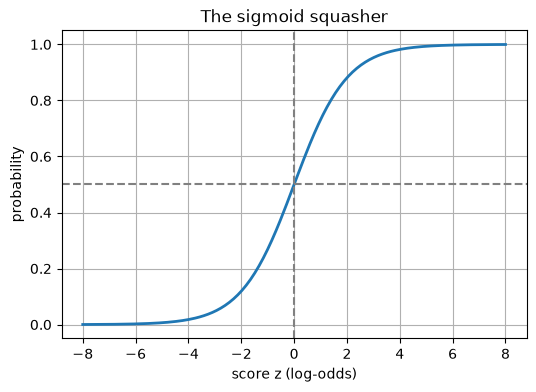

In [5]:
z = np.linspace(-8, 8, 200)         # 200 evenly spaced numbers from -8 to 8
plt.plot(z, sigmoid(z), lw=2)       # draw z on the x-axis, sigmoid(z) on the y-axis
plt.axhline(0.5, color="gray", ls="--")   # dashed line at probability 0.5
plt.axvline(0, color="gray", ls="--")     # dashed line at score 0
plt.xlabel("score z (log-odds)"); plt.ylabel("probability")   # label axes
plt.title("The sigmoid squasher"); plt.show()   # title and display

#### 📖 How to read this plot

- **Axes:** x = the raw score z (can be any number); y = the probability that comes out (0 to 1).
- **A good result looks like:** A smooth 'S'. Big negative scores give probabilities near 0, big positive near 1, and z=0 gives 0.5.
- **A bad result looks like:** A flat line, or a curve that goes below 0 or above 1 (that would not be a probability).
- **What this plot tells us:** No matter how extreme the score, the sigmoid always returns a valid probability. It is steepest around 0, so the model is most 'changeable' near 50/50 and gets more confident slowly at the ends.

**Common beginner mistake:** thinking the sigmoid output is a *guarantee*. σ(z)=0.9 means "the model believes 90%". That is only true if the model is **calibrated** (Step 7b).

### 🧠 Check yourself

What is sigmoid(0), and why?

<details><summary>👉 Click for the answer</summary>

**0.5.** e⁰ = 1, so 1/(1+1) = 0.5. A score of zero means odds of 1, a coin flip.

</details>

### Recap in 3 bullets

- Odds = p/(1−p); log-odds = ln(odds) stretches probabilities to any real number.
- Logistic regression models the log-odds as a straight line: z = b + w·x.
- The sigmoid is the inverse of log-odds: it turns the score z back into a probability.

**If you remember only one thing:** the sigmoid turns any score into a probability between 0 and 1.

---
## 1.4 Why not just use linear regression for yes/no?
**Idea (one sentence):** A straight line can output −5 or 12, which are not probabilities, and it is thrown off by extreme points.

**Analogy:** Using a ruler to predict a light switch. A switch is only ON or OFF, but a ruler happily reads "−3 centimeters" or "17 centimeters" of on-ness.

**Tiny example by hand:** Suppose a line predicts `y = 0.1·tenure − 0.2`. A customer with tenure 0 gets **−0.2** (a "negative 20% chance"), and one with tenure 12 gets **1.0**; tenure 20 gets **1.8** ("180%"). Impossible.

**Two failures:**
1. **Impossible outputs**, below 0 or above 1.
2. **Sensitive to far-away points.** One super-loyal customer drags the line and shifts predictions for everyone else.
We'll *see* this below.

### What we're about to do
Make 40 toy customers (x = months with company; y = 1 if churned). Fit a straight line (linear regression) and a sigmoid curve (we'll hand-pick its shape for now) and compare.

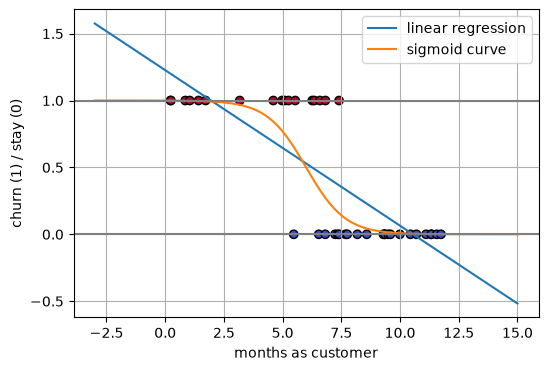

In [6]:
rng = np.random.RandomState(0)                       # a reproducible random generator
x = np.sort(rng.uniform(0, 12, 40))                  # 40 tenures between 0 and 12 months
y = (x + rng.normal(0, 2, 40) < 6).astype(int)       # short tenure -> likely churn (1), with noise
slope, icpt = np.polyfit(x, y, 1)                    # fit the best straight line to y
xs = np.linspace(-3, 15, 100)                        # x range to draw lines over (beyond data)
plt.scatter(x, y, c=y, cmap="coolwarm", edgecolor="k")   # draw the customers
plt.plot(xs, slope*xs + icpt, label="linear regression")  # the straight line
plt.plot(xs, sigmoid(-1.2*(xs-6)), label="sigmoid curve")  # a hand-picked sigmoid
plt.axhline(0, c="gray"); plt.axhline(1, c="gray")   # the legal range 0..1
plt.xlabel("months as customer"); plt.ylabel("churn (1) / stay (0)"); plt.legend(); plt.show()

#### 📖 How to read this plot

- **Axes:** x = months as customer; y = churned (1) or stayed (0). Dots are customers (red = churned), the lines are predictions.
- **A good result looks like:** A prediction line that stays between 0 and 1 and bends toward the dots at each end, like the sigmoid.
- **A bad result looks like:** A line that crosses below 0 or above 1 (impossible probabilities), like the straight line at the far left/right.
- **What this plot tells us:** The straight line leaves the 0-to-1 box, so it can't be read as a probability. The sigmoid hugs 0 and 1 and respects the rules.

### What we just saw (code line by line)
- `rng.uniform(0, 12, 40)` draws 40 random tenures; `np.sort` orders them.
- `(x + noise < 6).astype(int)` makes churn = 1 when (tenure + a bit of noise) is under 6, turning True/False into 1/0.
- `np.polyfit(x, y, 1)` finds the best straight line; it returns its slope and intercept.
- `plt.scatter` draws dots coloured by `y`; `plt.plot` draws the two prediction curves.

**Common beginner mistake:** "clipping" a linear model's output to 0–1 and calling it logistic regression. Clipping fixes the range but not the bad shape or the training problems.

### 🧠 Check yourself

Name one reason linear regression is a poor choice for yes/no.

<details><summary>👉 Click for the answer</summary>

Its predictions can be below 0 or above 1, so they aren't probabilities. (Also: extreme points pull the line.)

</details>

### Recap in 3 bullets

- Linear regression can output impossible values (−0.2, 1.8) as 'probabilities'.
- The sigmoid fixes the range: the output is always between 0 and 1.
- Logistic regression = straight line for the score, then a sigmoid to get a probability.

**If you remember only one thing:** use the sigmoid on top of the straight line so predictions are real probabilities.

---
## 1.5 Log-loss (cross-entropy): how wrong is the model?
**Idea (one sentence):** Log-loss is a score that punishes the model more, the more confident it was in the wrong answer.

**Analogy:** A quiz show where you bet points. Being right with high confidence earns almost no penalty; being *confidently wrong* costs a fortune; being unsure costs a medium amount.

**Tiny example by hand:** The customer **really did churn (y = 1)**. Loss for one customer = `−ln(p)` where p = probability we gave to the truth.
- Model said p = 0.9 → loss = −ln(0.9) = **0.105** (small, good!)
- Model said p = 0.5 → loss = −ln(0.5) = **0.693**
- Model said p = 0.1 → loss = −ln(0.1) = **2.303** (confidently wrong, big!)
- Model said p = 0.01 → loss = **4.605** (huge!)
If the customer **stayed (y = 0)**, we use `−ln(1−p)` instead: the probability we gave to "stays".

**Derivation: one small step per line.**
Let `p` = model's probability of churn, `y` = truth (1 or 0).

| Step | Line | Plain-English note |
|---|---|---|
| 1 | `P(one customer) = p^y · (1−p)^(1−y)` | If y=1 this is p; if y=0 it is (1−p). It's "the probability the model gave the truth" |
| 2 | `L = P₁ · P₂ · … · Pₙ` | **Likelihood:** probability of all n customers' truths together (multiply them) |
| 3 | `ln L = ln P₁ + ln P₂ + … + ln Pₙ` | Take ln: multiplying becomes adding (log rule from our refresher). Sums are stable and easy |
| 4 | `ln P = y·ln(p) + (1−y)·ln(1−p)` | ln turns the powers into multipliers |
| 5 | `Loss = −(1/n) · Σ [ y·ln(p) + (1−y)·ln(1−p) ]` | Flip the sign (we want to *minimize* a loss, not maximize) and average over n |

`Σ` (capital sigma) just means "add up over all customers", and `1/n` turns the total into an average.
So **minimizing log-loss = finding the weights that make the real outcomes as likely as possible** (this is called *maximum likelihood*).

**Why not just count mistakes?** Counting mistakes jumps in steps, so we can't tell which direction to nudge the weights. Log-loss is smooth, so gradient descent (Step 3) can follow it downhill.

In [7]:
def log_loss(y, p, eps=1e-12):                 # average log-loss over all customers
    p = np.clip(p, eps, 1 - eps)               # keep p away from exactly 0 or 1 (ln(0) breaks)
    return -np.mean(y*np.log(p) + (1-y)*np.log(1-p))   # the formula from step 5

y_true = np.array([1, 1, 0, 0])                # real outcomes
print("good model :", log_loss(y_true, np.array([.9, .8, .1, .2])))   # right and confident
print("unsure     :", log_loss(y_true, np.array([.5, .5, .5, .5])))   # coin flips
print("wrong+sure :", log_loss(y_true, np.array([.1, .2, .9, .8])))   # confidently wrong

good model : 0.164252033486018
unsure     : 0.6931471805599453
wrong+sure : 1.956011502714073


### What we just saw (code line by line)
- `np.clip(p, eps, 1-eps)` forces p into a safe range. Without it, p = 0 would give ln(0) = −∞, a crash.
- `np.mean(...)` is the `(1/n) Σ` part: add up and divide by count.
- `y*np.log(p)` only counts when y=1; `(1-y)*np.log(1-p)` only counts when y=0.
Good model ≈ 0.16, coin flips ≈ 0.693, confidently wrong ≈ 1.9. Lower is better.

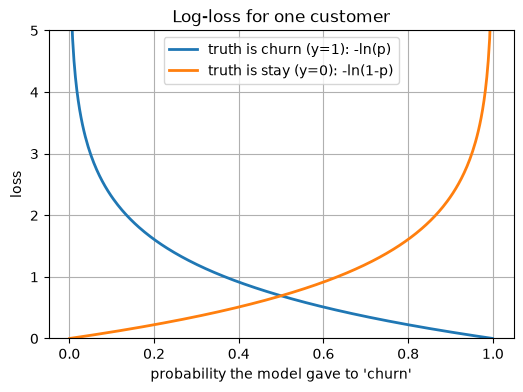

In [8]:
p = np.linspace(0.001, 0.999, 300)           # possible probabilities for a true-churner
plt.plot(p, -np.log(p), lw=2, label="truth is churn (y=1): -ln(p)")      # loss when y=1
plt.plot(p, -np.log(1-p), lw=2, label="truth is stay (y=0): -ln(1-p)")   # loss when y=0
plt.ylim(0, 5); plt.xlabel("probability the model gave to 'churn'"); plt.ylabel("loss")
plt.legend(); plt.title("Log-loss for one customer"); plt.show()

#### 📖 How to read this plot

- **Axes:** x = the probability the model gave to 'churn'; y = the penalty (loss) for one customer.
- **A good result looks like:** Loss near 0: the model put p close to 1 for a real churner (blue curve, right side) or close to 0 for a stayer (orange curve, left side).
- **A bad result looks like:** Loss shooting up: p near 0 for a real churner, or near 1 for a stayer (confident and wrong).
- **What this plot tells us:** The penalty grows sharply, not gently, as the model becomes confidently wrong. That pushes the model to be honest about its uncertainty.

**Common beginner mistake:** forgetting to clip probabilities, and then a single p of exactly 0 or 1 makes the loss `inf` or `nan`.

### 🧠 Check yourself

The customer churned (y=1). Model gave p=0.25. What is the loss for this customer?

<details><summary>👉 Click for the answer</summary>

−ln(0.25) = **1.386**.

</details>

### Recap in 3 bullets

- Log-loss = average of −ln(probability given to the truth).
- It comes from maximum likelihood: multiply probabilities, take logs, flip the sign.
- It punishes confident wrong answers very hard and is smooth, so we can minimize it.

**If you remember only one thing:** log-loss rewards honest, correct probabilities and brutally punishes confident mistakes.

---
## 1.6 Decision boundaries
**Idea (one sentence):** The decision boundary is the line where the model switches from saying "stay" to "leave".

**Analogy:** A fence in a field. Customers on one side are predicted to leave, on the other side to stay. The fence stands where the probability is exactly 50% (or whatever threshold we pick).

**Tiny example by hand:** with two features, `z = −3 + 1·x₁ + 1·x₂`.
- Probability = 0.5 exactly when z = 0 (we showed sigmoid(0)=0.5).
- So the boundary is `x₁ + x₂ = 3`, a straight line.
- Point (1, 1): z = −1 → p ≈ 0.27 → "stay". Point (3, 2): z = +2 → p ≈ 0.88 → "leave".

**The math in words:** boundary is where `b + w₁x₁ + w₂x₂ = 0`. Since the score is a straight line in the features, the boundary is a straight line (a flat plane with more features). That is why logistic regression is called a **linear classifier**.
We draw the real one in Step 3.

In [9]:
def score(x1, x2):                  # the hand example: z = -3 + x1 + x2
    return -3 + x1 + x2

for pt in [(1, 1), (3, 2), (1.5, 1.5)]:           # three customers (x1, x2)
    z = score(*pt)                                # their score
    print(pt, f"z={z:+.1f}  p={sigmoid(z):.2f}")  # score and probability

(1, 1) z=-1.0  p=0.27
(3, 2) z=+2.0  p=0.88
(1.5, 1.5) z=+0.0  p=0.50


### What we just saw
(1,1) gives p=0.27 (stay), (3,2) gives p=0.88 (leave), and (1.5,1.5) sits exactly on the fence (z=0, p=0.50). `*pt` unpacks the pair (1,1) into the two inputs x1 and x2.

**Common beginner mistake:** assuming the boundary is always at probability 0.5. 0.5 is just a default. In Step 6 we'll move it to save money.

### 🧠 Check yourself

A model has z = 2 − x₁ (one feature). At what x₁ is the boundary?

<details><summary>👉 Click for the answer</summary>

Set z = 0: 2 − x₁ = 0 → **x₁ = 2**.

</details>

### Recap in 3 bullets

- The boundary is where the score z is 0 (probability = threshold).
- Because z is a straight line in the features, the boundary is a straight line/plane.
- Moving the threshold moves the fence, a choice we'll make by money (Step 6).

**If you remember only one thing:** the decision boundary is simply where the model's probability crosses your chosen threshold.

---
# ✅ Step 1 summary
**Recap in 3 bullets**
- Probability → odds → log-odds; logistic regression makes log-odds a straight line.
- Sigmoid converts the score back into a 0-to-1 probability; log-loss trains it.
- The decision boundary is where probability hits the threshold.

**If you remember only one thing:** logistic regression = *straight-line score → sigmoid → probability → threshold → decision*.